In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

conn = sqlite3.connect("tickets.db")
df = pd.read_sql("SELECT * FROM games_clean WHERE covid_capacity_limit = 0", conn)
conn.close()

print(df.shape)   # expect (452, ...) -> 485 minus the 33 capacity-limited games

(904, 23)


In [2]:
df.head()

,team,game_pk,season,official_date,first_pitch_local,opponent,attendance,day_of_week,is_weekend,month,...,opp_win_pct_pre,games_played_pre,is_rival,is_doubleheader,covid_capacity_limit,temp_f,is_hot,humidity,cloud_cover,wind_mph
0,dodgers,633675,2021,2021-06-15,2021-06-15 19:10:00,Philadelphia Phillies,52078,2,0,6,...,0.500,66,0,0,0,83.4,0,30,92,5.8
1,dodgers,633677,2021,2021-06-16,2021-06-16 19:10:00,Philadelphia Phillies,52157,3,0,6,...,0.492,67,0,0,0,77.1,0,45,86,10.9
2,dodgers,633505,2021,2021-06-24,2021-06-24 19:10:00,Chicago Cubs,52175,4,0,6,...,0.554,74,0,0,0,69.2,0,57,0,7.9
3,dodgers,633608,2021,2021-06-25,2021-06-25 19:10:00,Chicago Cubs,49387,5,1,6,...,0.560,75,0,0,0,71.9,0,53,0,7.6
4,dodgers,633562,2021,2021-06-26,2021-06-26 16:15:00,Chicago Cubs,45420,6,1,6,...,0.553,76,0,0,0,83.4,0,38,3,9.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 904 entries, 0 to 903
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   team                  904 non-null    str    
 1   game_pk               904 non-null    int64  
 2   season                904 non-null    int64  
 3   official_date         904 non-null    str    
 4   first_pitch_local     904 non-null    str    
 5   opponent              904 non-null    str    
 6   attendance            904 non-null    int64  
 7   day_of_week           904 non-null    int64  
 8   is_weekend            904 non-null    int64  
 9   month                 904 non-null    int64  
 10  start_hour            904 non-null    int64  
 11  is_night              904 non-null    int64  
 12  team_win_pct_pre      901 non-null    float64
 13  opp_win_pct_pre       899 non-null    float64
 14  games_played_pre      904 non-null    int64  
 15  is_rival              904 non-null

In [4]:
df["official_date"] = pd.to_datetime(df["official_date"])
df["first_pitch_local"] = pd.to_datetime(df["first_pitch_local"])

In [5]:
df[df['covid_capacity_limit'] > 0]

,team,game_pk,season,official_date,first_pitch_local,opponent,attendance,day_of_week,is_weekend,month,...,opp_win_pct_pre,games_played_pre,is_rival,is_doubleheader,covid_capacity_limit,temp_f,is_hot,humidity,cloud_cover,wind_mph


In [6]:
# drop column since there are no values for it
df = df.drop('covid_capacity_limit', axis = 1)

In [7]:
# fill the missing win percentages with 0.5 to give both teams 50/50 chance of winning that game
df = df.fillna(0.5)

In [8]:
dodgers_df = df[df['team'] == 'dodgers']
angels_df = df[df['team'] == 'angels']

<Axes: xlabel='day_of_week'>

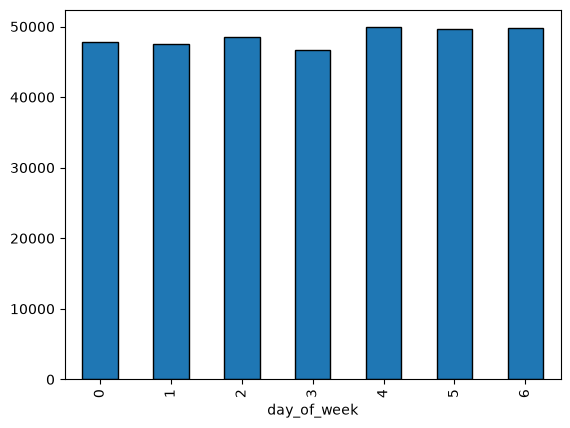

In [9]:
import matplotlib.pyplot as plt
%matplotlib inline

dodgers_df.groupby("day_of_week")["attendance"].mean().plot(kind="bar", edgecolor="black")

<Axes: xlabel='day_of_week'>

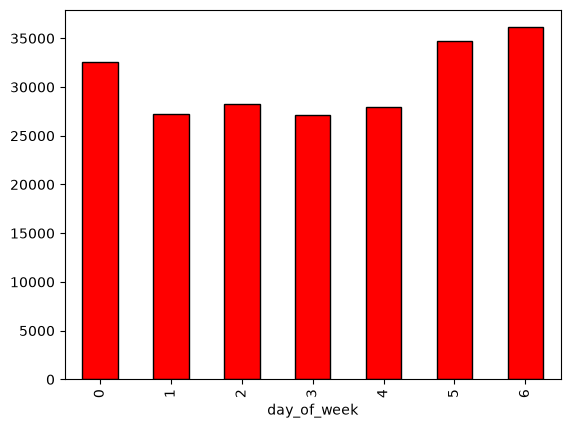

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

angels_df.groupby("day_of_week")["attendance"].mean().plot(kind="bar", edgecolor="black", color = 'red')

## Dodgers Analysis

In [11]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

FEATURES = ["season", "day_of_week", "month", "start_hour",
            "team_win_pct_pre", "opp_win_pct_pre", "is_doubleheader",
            "temp_f", "humidity", "cloud_cover", "wind_mph"]
WINPCT_COLS = ["team_win_pct_pre", "opp_win_pct_pre"]
CAT_COLS = ["day_of_week", "month"]


def make_linear(features):
    num_cols = [c for c in features if c not in WINPCT_COLS + CAT_COLS]
    preprocessor = ColumnTransformer(transformers=[
        ("winpct", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value=0.5)),
            ("scaler", StandardScaler()),
        ]), WINPCT_COLS),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=[0, 4]), CAT_COLS),  # Sunday, April
    ])
    return Pipeline([("prep", preprocessor), ("model", LinearRegression())])


def run_baseline(df, features=FEATURES):
    train_df, test_df = df[df["season"] != 2026], df[df["season"] == 2026]
    X_train, y_train = train_df[features], train_df["attendance"]
    X_test,  y_test  = test_df[features],  test_df["attendance"]

    linear_model = make_linear(features).fit(X_train, y_train)
    gb_model = HistGradientBoostingRegressor(random_state=42).fit(X_train, y_train)

    preds = {
        "Baseline (2025 avg)": [train_df.loc[train_df["season"] == 2025, "attendance"].mean()] * len(y_test),
        "Linear Regression": linear_model.predict(X_test),
        "Gradient Boosting": gb_model.predict(X_test),
    }
    results = pd.DataFrame({
        "model": list(preds),
        "MAE": [mean_absolute_error(y_test, p) for p in preds.values()],
    }).round(0)
    coefs = pd.Series(
        linear_model.named_steps["model"].coef_,
        index=linear_model.named_steps["prep"].get_feature_names_out(),
    ).sort_values()

    return {"results": results, "coefs": coefs, "test_df": test_df,
            "linear_preds": preds["Linear Regression"], "gb_preds": preds["Gradient Boosting"], "linear_model": linear_model}


dodgers = run_baseline(dodgers_df)

print("DODGERS\n", dodgers["results"])

DODGERS
                  model     MAE
0  Baseline (2025 avg)  2315.0
1    Linear Regression  2165.0
2    Gradient Boosting  2515.0


In [12]:
print(dodgers["coefs"])

cat__day_of_week_1         -4870.542849
cat__day_of_week_3         -3924.221944
cat__day_of_week_2         -3256.519605
cat__month_9               -2748.135469
cat__day_of_week_5         -2561.525540
cat__month_5               -2407.934392
cat__month_8               -1951.030338
cat__day_of_week_4         -1708.233150
cat__month_7               -1611.312510
cat__day_of_week_6         -1479.464399
cat__month_10              -1366.916737
cat__month_3               -1193.877275
num__humidity               -375.686110
cat__month_6                -271.912387
num__is_doubleheader        -108.407200
num__temp_f                   32.146146
num__cloud_cover              58.773024
num__wind_mph                 75.643492
winpct__team_win_pct_pre     265.176053
winpct__opp_win_pct_pre      348.703242
num__season                  786.149553
num__start_hour             2185.030062
dtype: float64


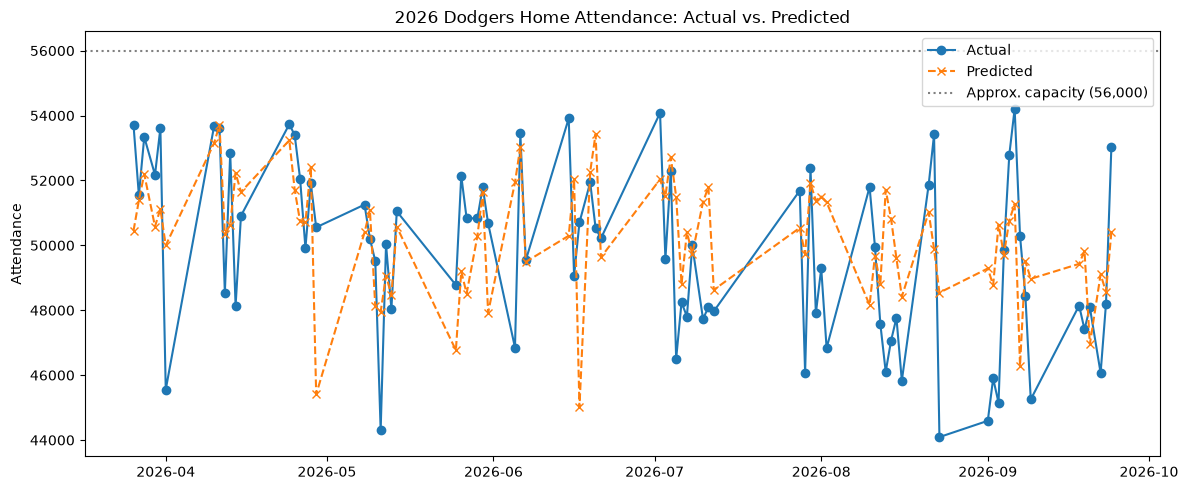

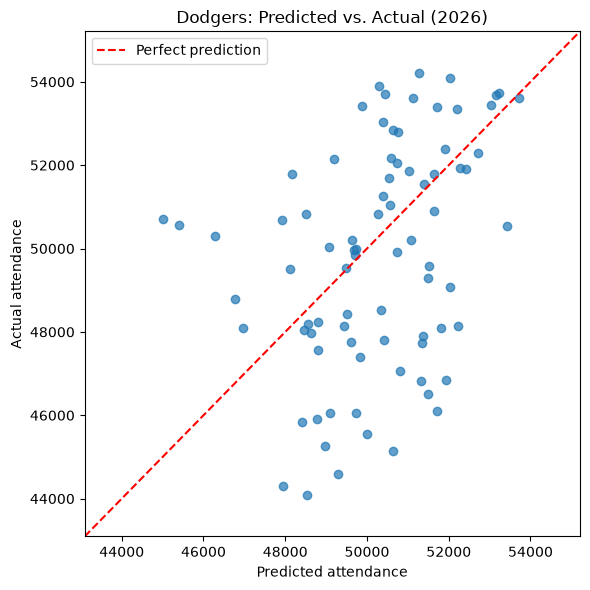

DODGERS - most UNDER-predicted (beat expectations):
official_date           opponent  attendance  predicted  error
   2026-06-17     Tampa Bay Rays       50705    45004.0 5701.0
   2026-04-29      Miami Marlins       50555    45409.0 5146.0
   2026-09-07    Cincinnati Reds       50293    46291.0 4002.0
   2026-08-10 Kansas City Royals       51799    48162.0 3637.0
   2026-06-15     Tampa Bay Rays       53911    50296.0 3615.0

DODGERS - most OVER-predicted (fell short):
official_date            opponent  attendance  predicted   error
   2026-08-13   Milwaukee Brewers       46105    51713.0 -5608.0
   2026-09-03 St. Louis Cardinals       45150    50640.0 -5490.0
   2026-06-05  Los Angeles Angels       46850    51939.0 -5089.0
   2026-07-05    San Diego Padres       46506    51498.0 -4992.0
   2026-09-01 St. Louis Cardinals       44593    49287.0 -4694.0


C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\2676770366.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(dodgers_2026.nlargest(5, "error")[cols].round(0).to_string(index=False))
C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\2676770366.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(dodgers_2026.nsmallest(5, "error")[cols].round(0).to_string(index=False))


In [13]:
import matplotlib.pyplot as plt

# ===================== DODGERS: 2026 actual vs. predicted =====================
# Best model for the Dodgers: Linear Regression

dodgers_2026 = dodgers["test_df"][["official_date", "opponent", "day_of_week", "attendance"]].copy()
dodgers_2026["predicted"] = dodgers["linear_preds"]
dodgers_2026["error"] = dodgers_2026["attendance"] - dodgers_2026["predicted"]
dodgers_2026 = dodgers_2026.sort_values("official_date")

# 1) Season timeline
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dodgers_2026["official_date"], dodgers_2026["attendance"], marker="o", label="Actual")
ax.plot(dodgers_2026["official_date"], dodgers_2026["predicted"], marker="x", linestyle="--", label="Predicted")
ax.axhline(56000, color="gray", linestyle=":", label="Approx. capacity (56,000)")
ax.set_title("2026 Dodgers Home Attendance: Actual vs. Predicted")
ax.set_ylabel("Attendance")
ax.legend()
plt.tight_layout()
plt.show()

# 2) Predicted vs. actual scatter
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(dodgers_2026["predicted"], dodgers_2026["attendance"], alpha=0.7)
lims = [dodgers_2026[["attendance", "predicted"]].min().min() - 1000,
        dodgers_2026[["attendance", "predicted"]].max().max() + 1000]
ax.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Predicted attendance")
ax.set_ylabel("Actual attendance")
ax.set_title("Dodgers: Predicted vs. Actual (2026)")
ax.legend()
plt.tight_layout()
plt.show()

# 3) Biggest misses
cols = ["official_date", "opponent", "attendance", "predicted", "error"]
print("DODGERS - most UNDER-predicted (beat expectations):")
print(dodgers_2026.nlargest(5, "error")[cols].round(0).to_string(index=False))
print("\nDODGERS - most OVER-predicted (fell short):")
print(dodgers_2026.nsmallest(5, "error")[cols].round(0).to_string(index=False))

## Were the significant misses on a promotion night?

In [14]:
# ── Promotion analysis: do some promo types beat the model's prediction? ──
# Paste into your notebook AFTER the cell that builds `results_2026`
# (columns: official_date, opponent, day_of_week, attendance, predicted, error).
# Put dodgers_promos_2026.csv in your project folder first.

import pandas as pd
from scipy import stats

promos = pd.read_csv("dodgers_promos_2026.csv", parse_dates=["official_date"])

res = dodgers_2026.merge(promos, on="official_date", how="left")
res["promo_category"] = res["promo_category"].fillna("no_promo")

# Holidays are a separate effect - flag them so they don't get credited to promos
holidays = pd.to_datetime(["2026-05-25", "2026-07-04", "2026-09-07"])  # Memorial Day, July 4, Labor Day
res["is_holiday"] = res["official_date"].isin(holidays).astype(int)

# 1) Average error by promo category (error = actual - predicted; positive = beat the model)
summary = (
    res.groupby("promo_category")
       .agg(games=("error", "size"),
            avg_error=("error", "mean"),
            median_error=("error", "median"),
            avg_attendance=("attendance", "mean"))
       .sort_values("avg_error", ascending=False)
       .round(0)
)
print(summary)

# 2) Is each category different from everything else? (Welch t-test, two-sided)
print("\nCategory vs. all other games:")
for cat in summary.index:
    in_cat = res.loc[res["promo_category"] == cat, "error"]
    rest = res.loc[res["promo_category"] != cat, "error"]
    if len(in_cat) >= 3:
        t, p = stats.ttest_ind(in_cat, rest, equal_var=False)
        print(f"  {cat:22s} n={len(in_cat):2d}  diff={in_cat.mean() - rest.mean():7.0f}  p={p:.2f}")
    else:
        print(f"  {cat:22s} n={len(in_cat):2d}  (too few games to test)")

# 3) Game-level detail for the categories tied to your cultural-impact idea
cols = ["official_date", "opponent", "promo_item", "attendance", "predicted", "error", "is_holiday"]
for cat in ["heritage_night", "celebrity_crossover", "pop_culture"]:
    print(f"\n--- {cat} ---")
    print(res.loc[res["promo_category"] == cat, cols].sort_values("error", ascending=False).round(0).to_string(index=False))

# Save for Power BI
res.to_csv("dodgers_2026_predictions_with_promos.csv", index=False)

                      games  avg_error  median_error  avg_attendance
promo_category                                                      
player_bobblehead        23      408.0         524.0         50884.0
apparel_other             8     -110.0         -77.0         49105.0
family_day                3     -472.0          45.0         47816.0
ticket_package_night      7     -540.0         -92.0         50398.0
no_promo                 10     -696.0        -825.0         49179.0
pop_culture               8     -750.0        -378.0         49737.0
heritage_night           10    -1129.0        -936.0         49484.0
celebrity_crossover       4    -1191.0       -1016.0         50135.0
championship_item         6    -1208.0       -1649.0         48028.0
fireworks_holiday         2    -1322.0       -1322.0         50788.0

Category vs. all other games:
  player_bobblehead      n=23  diff=   1183  p=0.05
  apparel_other          n= 8  diff=    366  p=0.76
  family_day             n= 3  diff= 

C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\2861880099.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(res.loc[res["promo_category"] == cat, cols].sort_values("error", ascending=False).round(0).to_string(index=False))
C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\2861880099.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(res.loc[res["promo_category"] == cat, cols].sort_values("error", ascending=False).round(0).to_string(index=False))
C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\2861880099.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(res.loc[res["promo_category"] == cat, cols].sort_values("error", ascending=False).round(0).to_string(index=False))


### Bobbleheads seem to increase attendance, does the type of bobblehead affect this as well?

In [15]:
# ── Promo analysis v2: star vs. role bobbleheads, tested on 2025 AND 2026 (DODGERS ONLY) ──
# Needs: dodgers_df and make_linear() from earlier cells.
# Put dodgers_promos_2025_2026.csv in your project folder first.

from scipy import stats

# Separate name so it doesn't overwrite FEATURES used by the other cells
PROMO_FEATURES = ["season", "day_of_week", "month", "start_hour",
                  "team_win_pct_pre", "opp_win_pct_pre", "is_doubleheader",
                  "temp_f", "humidity", "cloud_cover", "wind_mph"]


def predict_season(test_season):
    """Train on every Dodgers season BEFORE test_season, predict test_season (out-of-sample)."""
    train = dodgers_df[dodgers_df["season"] < test_season]
    test  = dodgers_df[dodgers_df["season"] == test_season]
    model = make_linear(PROMO_FEATURES).fit(train[PROMO_FEATURES], train["attendance"])
    out = test[["official_date", "season", "opponent", "day_of_week", "attendance"]].copy()
    out["predicted"] = model.predict(test[PROMO_FEATURES])
    out["error"] = out["attendance"] - out["predicted"]
    print(f"{test_season}: trained on {train['season'].min()}-{train['season'].max()}, "
          f"MAE = {mean_absolute_error(out['attendance'], out['predicted']):.0f}")
    return out


promo_res = pd.concat([predict_season(2025), predict_season(2026)], ignore_index=True)

promos = pd.read_csv("dodgers_promos_2025_2026.csv", parse_dates=["official_date"])
promo_res = promo_res.merge(promos.drop(columns="season"), on="official_date", how="left")
promo_res["promo_category"] = promo_res["promo_category"].fillna("no_listed_promo")

# Sanity check: every promo date should match a home game
unmatched = promos[~promos["official_date"].isin(promo_res["official_date"])]
print(f"\nPromo dates with no matching home game: {len(unmatched)}")
print(unmatched[["official_date", "promo_item"]].to_string(index=False))

BOBBLE = ["star_bobblehead", "role_bobblehead", "legend_bobblehead", "celebrity_crossover"]
promo_res["any_bobblehead"] = promo_res["promo_category"].isin(BOBBLE)


def compare(data, mask, label):
    a, b = data.loc[mask, "error"], data.loc[~mask, "error"]
    if len(a) < 3:
        print(f"  {label:32s} n={len(a):2d}  (too few to test)")
        return
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"  {label:32s} n={len(a):2d}  avg_error={a.mean():6.0f}  diff_vs_rest={a.mean() - b.mean():6.0f}  p={p:.3f}")


# 1) Bobblehead tiers, each season separately and pooled
for season in [2025, 2026, "pooled"]:
    print(f"\n=== {season} ===")
    sub = promo_res if season == "pooled" else promo_res[promo_res["season"] == season]
    compare(sub, sub["any_bobblehead"], "any bobblehead")
    for cat in BOBBLE:
        compare(sub, sub["promo_category"] == cat, cat)

# 2) Full category table (2026 has complete theme-night data; 2025 is giveaways only)
print("\n=== Category averages by season ===")
print(promo_res.pivot_table(index="promo_category", columns="season", values="error",
                            aggfunc=["count", "mean"]).round(0))

# 3) Star bobblehead games, one by one
print("\n=== Star bobblehead games ===")
cols = ["official_date", "opponent", "day_of_week", "promo_item", "attendance", "predicted", "error"]
print(promo_res.loc[promo_res["promo_category"] == "star_bobblehead", cols]
         .sort_values("official_date").round({"predicted": 0, "error": 0}).to_string(index=False))

promo_res.to_csv("dodgers_2025_2026_predictions_with_promos.csv", index=False)

2025: trained on 2021-2024, MAE = 3030
2026: trained on 2021-2025, MAE = 2165

Promo dates with no matching home game: 0
Empty DataFrame
Columns: [official_date, promo_item]
Index: []

=== 2025 ===
  any bobblehead                   n=23  avg_error=   463  diff_vs_rest=   481  p=0.615
  star_bobblehead                  n= 9  avg_error=  1659  diff_vs_rest=  1733  p=0.156
  role_bobblehead                  n= 9  avg_error=  -385  diff_vs_rest=  -567  p=0.737
  legend_bobblehead                n= 3  avg_error= -1927  diff_vs_rest= -2124  p=0.506
  celebrity_crossover              n= 2  (too few to test)

=== 2026 ===
  any bobblehead                   n=27  avg_error=   171  diff_vs_rest=   916  p=0.116
  star_bobblehead                  n=10  avg_error=   222  diff_vs_rest=   755  p=0.374
  role_bobblehead                  n=12  avg_error=   748  diff_vs_rest=  1395  p=0.047
  legend_bobblehead                n= 1  (too few to test)
  celebrity_crossover              n= 4  avg_error= -1

## Angels Analysis

In [16]:
angels = run_baseline(angels_df)

print("ANGELS\n", angels["results"])

ANGELS
                  model     MAE
0  Baseline (2025 avg)  5747.0
1    Linear Regression  4997.0
2    Gradient Boosting  4215.0


In [17]:
print(angels["coefs"])

cat__day_of_week_1         -12528.381575
cat__day_of_week_2         -11818.381392
cat__day_of_week_3         -10317.554674
cat__day_of_week_4          -9989.826356
cat__day_of_week_5          -5577.092702
cat__day_of_week_6          -3916.848653
cat__month_5                -2186.729335
cat__month_7                -1725.720386
cat__month_9                -1393.622099
cat__month_10               -1197.524157
cat__month_6                 -452.511834
num__humidity                -419.091057
num__is_doubleheader         -310.086765
num__temp_f                    32.462999
cat__month_8                  172.418170
num__cloud_cover              204.752406
winpct__team_win_pct_pre      951.785795
num__wind_mph                1228.967015
winpct__opp_win_pct_pre      1730.283567
num__season                  2877.867049
num__start_hour              3493.712050
dtype: float64


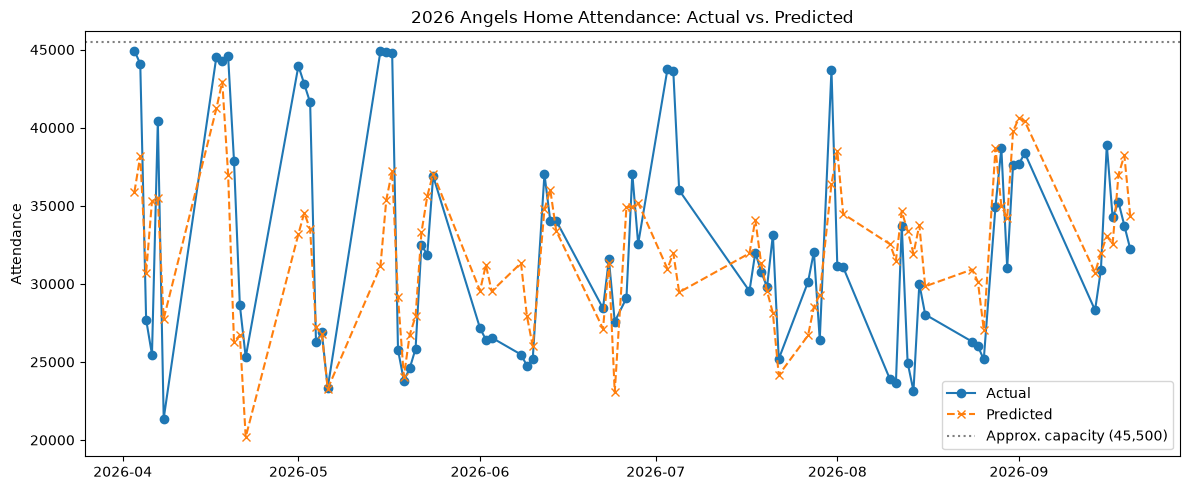

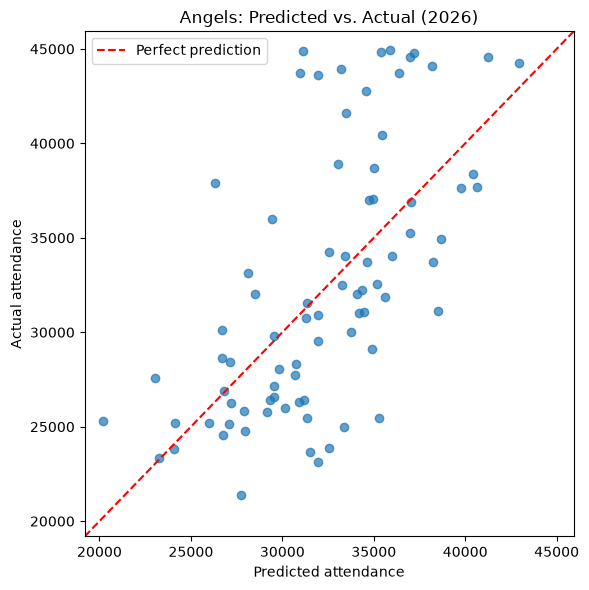

ANGELS - most UNDER-predicted (beat expectations):
official_date            opponent  attendance  predicted   error
   2026-05-15 Los Angeles Dodgers       44887    31123.0 13764.0
   2026-07-03      Boston Red Sox       43747    30962.0 12785.0
   2026-07-04      Boston Red Sox       43599    31969.0 11630.0
   2026-04-20   Toronto Blue Jays       37897    26302.0 11595.0
   2026-05-01       New York Mets       43959    33190.0 10769.0

ANGELS - most OVER-predicted (fell short):
official_date           opponent  attendance  predicted   error
   2026-04-06     Atlanta Braves       25471    35296.0 -9825.0
   2026-08-14 Kansas City Royals       23139    31938.0 -8799.0
   2026-08-10      Texas Rangers       23880    32537.0 -8657.0
   2026-08-13      Texas Rangers       24959    33389.0 -8430.0
   2026-08-11      Texas Rangers       23648    31490.0 -7842.0


C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\3566911535.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(angels_2026.nlargest(5, "error")[cols].round(0).to_string(index=False))
C:\Users\pmari\AppData\Local\Temp\ipykernel_22312\3566911535.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(angels_2026.nsmallest(5, "error")[cols].round(0).to_string(index=False))


In [18]:
# ===================== ANGELS: 2026 actual vs. predicted =====================
# Best model for the Angels: Gradient Boosting

angels_2026 = angels["test_df"][["official_date", "opponent", "day_of_week", "attendance"]].copy()
angels_2026["predicted"] = angels["gb_preds"]
angels_2026["error"] = angels_2026["attendance"] - angels_2026["predicted"]
angels_2026 = angels_2026.sort_values("official_date")

# 1) Season timeline
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(angels_2026["official_date"], angels_2026["attendance"], marker="o", label="Actual")
ax.plot(angels_2026["official_date"], angels_2026["predicted"], marker="x", linestyle="--", label="Predicted")
ax.axhline(45500, color="gray", linestyle=":", label="Approx. capacity (45,500)")
ax.set_title("2026 Angels Home Attendance: Actual vs. Predicted")
ax.set_ylabel("Attendance")
ax.legend()
plt.tight_layout()
plt.show()

# 2) Predicted vs. actual scatter
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(angels_2026["predicted"], angels_2026["attendance"], alpha=0.7)
lims = [angels_2026[["attendance", "predicted"]].min().min() - 1000,
        angels_2026[["attendance", "predicted"]].max().max() + 1000]
ax.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Predicted attendance")
ax.set_ylabel("Actual attendance")
ax.set_title("Angels: Predicted vs. Actual (2026)")
ax.legend()
plt.tight_layout()
plt.show()

# 3) Biggest misses
cols = ["official_date", "opponent", "attendance", "predicted", "error"]
print("ANGELS - most UNDER-predicted (beat expectations):")
print(angels_2026.nlargest(5, "error")[cols].round(0).to_string(index=False))
print("\nANGELS - most OVER-predicted (fell short):")
print(angels_2026.nsmallest(5, "error")[cols].round(0).to_string(index=False))

### Test again with a learned score

In [19]:
NAME_FIX = {"Oakland Athletics": "Athletics", "Cleveland Indians": "Cleveland Guardians"}
K = 10  # shrinkage: an opponent needs ~10 games before its own average gets half the weight


def add_opp_draw(df):
    """Adds a schedule-adjusted, shrunk opponent-draw score.
    Scores are learned from TRAINING seasons only (2021-2025), then applied to every game."""
    df = df.drop(columns="opp_draw", errors="ignore").copy()
    df["opponent"] = df["opponent"].replace(NAME_FIX)

    train = df[df["season"] != 2026]

    # Schedule-only model -> leftover attendance per training game
    base_model = make_linear(FEATURES).fit(train[FEATURES], train["attendance"])
    resid = train["attendance"] - base_model.predict(train[FEATURES])

    # Average leftover per opponent, shrunk toward 0 for small samples
    s = resid.groupby(train["opponent"]).agg(["sum", "count"])
    opp_draw = (s["sum"] / (s["count"] + K)).rename("opp_draw")

    df = df.join(opp_draw, on="opponent")
    df["opp_draw"] = df["opp_draw"].fillna(0)  # opponent never seen in training = neutral

    opp_table = (pd.DataFrame({"games": s["count"], "opp_draw": opp_draw.round(0)})
                   .sort_values("opp_draw", ascending=False))
    return df, opp_table

In [20]:
# ===================== ANGELS: + opponent draw =====================
angel_df_od, angels_opp_table = add_opp_draw(angels_df)
print(angels_opp_table.to_string())

angels_od = run_baseline(angel_df_od, features=FEATURES + ["opp_draw"])
print("\nANGELS (with opp_draw)\n", angels_od["results"])

                       games  opp_draw
opponent                              
Los Angeles Dodgers        9    5862.0
New York Yankees          15    5446.0
Chicago White Sox         13    1216.0
Minnesota Twins           12     812.0
Boston Red Sox            16     795.0
San Francisco Giants       8     783.0
San Diego Padres           5     654.0
Kansas City Royals        13     532.0
Pittsburgh Pirates         6     394.0
Washington Nationals       9     312.0
Chicago Cubs               6     248.0
Arizona Diamondbacks       6       6.0
Atlanta Braves             3     -46.0
Toronto Blue Jays         16    -362.0
New York Mets              6    -380.0
Athletics                 36    -510.0
Cleveland Guardians       14    -614.0
Houston Astros            35    -694.0
Texas Rangers             32    -816.0
Detroit Tigers            18    -822.0
Milwaukee Brewers          3    -848.0
St. Louis Cardinals        3    -875.0
Seattle Mariners          37    -960.0
Miami Marlins            

In [21]:
# ===================== DODGERS: + opponent draw =====================
dodger_df_od, dodgers_opp_table = add_opp_draw(dodgers_df)
print(dodgers_opp_table.to_string())

dodgers_od = run_baseline(dodger_df_od, features=FEATURES + ["opp_draw"])
print("\nDODGERS (with opp_draw)\n", dodgers_od["results"])

                       games  opp_draw
opponent                              
Los Angeles Angels        12    1026.0
New York Yankees           6     898.0
Baltimore Orioles          3     895.0
San Francisco Giants      36     847.0
Pittsburgh Pirates        16     706.0
Atlanta Braves            16     576.0
Cincinnati Reds           14     259.0
Minnesota Twins            8     205.0
St. Louis Cardinals       13     163.0
Houston Astros             8     150.0
San Diego Padres          35     148.0
Washington Nationals      12      76.0
Boston Red Sox             3      65.0
Kansas City Royals         3      21.0
Chicago Cubs              17      11.0
Seattle Mariners           3     -16.0
Tampa Bay Rays             3     -22.0
Chicago White Sox          6     -31.0
Miami Marlins             12     -39.0
Texas Rangers              3    -110.0
Athletics                  6    -137.0
Colorado Rockies          33    -163.0
Detroit Tigers             9    -248.0
Cleveland Guardians      

### Reading the coefficients

In [22]:
def per_unit_effects(run):
    m = run["linear_model"]
    prep = m.named_steps["prep"]
    coefs = pd.Series(m.named_steps["model"].coef_, index=prep.get_feature_names_out())
    rows = []
    for group, cols in [("winpct", WINPCT_COLS),
                        ("num", [c for c in prep.transformers_[1][2]])]:
        scaler = prep.named_transformers_[group].named_steps["scaler"]
        for col, sd in zip(cols, scaler.scale_):
            rows.append({"feature": col, "per_typical_change": coefs[f"{group}__{col}"],
                         "typical_change_size": sd,
                         "per_1_unit": coefs[f"{group}__{col}"] / sd})
    return pd.DataFrame(rows).round(2)

print(per_unit_effects(dodgers))
print(per_unit_effects(angels))

            feature  per_typical_change  typical_change_size  per_1_unit
0  team_win_pct_pre              265.18                 0.07     3755.25
1   opp_win_pct_pre              348.70                 0.12     2956.04
2            season              786.15                 1.34      586.92
3        start_hour             2185.03                 2.36      924.55
4   is_doubleheader             -108.41                 0.13     -859.43
5            temp_f               32.15                 9.13        3.52
6          humidity             -375.69                14.63      -25.68
7       cloud_cover               58.77                34.35        1.71
8          wind_mph               75.64                 2.26       33.44
            feature  per_typical_change  typical_change_size  per_1_unit
0  team_win_pct_pre              951.79                 0.07    13402.38
1   opp_win_pct_pre             1730.28                 0.11    15860.56
2            season             2877.87            

In [23]:
from sklearn.inspection import permutation_importance

def driver_ranking(run, df, features=FEATURES):
    test = df[df["season"] == 2026]
    pi = permutation_importance(run["linear_model"], test[features], test["attendance"],
                                scoring="neg_mean_absolute_error", n_repeats=30, random_state=42)
    return (pd.DataFrame({"feature": features,
                          "MAE_increase_if_removed": pi.importances_mean.round(0),
                          "spread": pi.importances_std.round(0)})
              .sort_values("MAE_increase_if_removed", ascending=False)
              .reset_index(drop=True))

print("DODGERS\n", driver_ranking(dodgers, dodgers_df))
print("\nANGELS\n", driver_ranking(angels, angels_df))

DODGERS
              feature  MAE_increase_if_removed  spread
0         start_hour                    702.0   177.0
1        day_of_week                    477.0   123.0
2              month                    320.0   134.0
3   team_win_pct_pre                     69.0    33.0
4    opp_win_pct_pre                     23.0    38.0
5        cloud_cover                     14.0     6.0
6             season                      0.0     0.0
7    is_doubleheader                      0.0     0.0
8             temp_f                     -5.0     3.0
9           wind_mph                     -5.0     3.0
10          humidity                    -29.0    34.0

ANGELS
              feature  MAE_increase_if_removed  spread
0        day_of_week                   2155.0   274.0
1         start_hour                   1131.0   308.0
2    opp_win_pct_pre                    166.0   114.0
3   team_win_pct_pre                     97.0    45.0
4           humidity                     62.0    39.0
5        c

In [24]:
print("ANGELS (with opp_draw)\n",
      driver_ranking(angels_od, angel_df_od, features=FEATURES + ["opp_draw"]))

ANGELS (with opp_draw)
              feature  MAE_increase_if_removed  spread
0        day_of_week                   2476.0   383.0
1         start_hour                   1023.0   239.0
2           opp_draw                    983.0   202.0
3           humidity                    182.0    80.0
4              month                    122.0    73.0
5   team_win_pct_pre                    115.0    38.0
6        cloud_cover                     23.0    32.0
7           wind_mph                     16.0    50.0
8             season                      0.0     0.0
9    is_doubleheader                      0.0     0.0
10   opp_win_pct_pre                    -12.0    80.0
11            temp_f                    -18.0    47.0


In [25]:
CAPACITY = {"dodgers": 56000, "angels": 45500}

# Capacity metrics on every game
df["capacity"] = df["team"].map(CAPACITY)
df["pct_capacity"] = (df["attendance"] / df["capacity"]).round(3)
df["empty_seats"] = df["capacity"] - df["attendance"]

# 2026 predictions with tiers (by predicted demand, within each team)
def add_tiers(res, team):
    res = res.copy()
    res["team"] = team
    res["capacity"] = CAPACITY[team]
    res["pred_pct_capacity"] = (res["predicted"] / res["capacity"]).round(3)
    res["empty_seats"] = res["capacity"] - res["attendance"]
    res["demand_tier"] = pd.qcut(res["predicted"].rank(method="first"),
                                 q=[0, 0.2, 0.5, 0.8, 1.0],
                                 labels=["Value", "Standard", "High", "Premium"])
    return res

d26 = add_tiers(dodgers_2026, "dodgers").assign(model="Linear Regression")
a26 = add_tiers(angels_2026, "angels").assign(model="Gradient Boosting")

In [2]:
from scipy import stats
import pandas as pd
p = pd.read_csv("dodgers_2025_2026_predictions_with_promos.csv")
star = p.loc[p["promo_category"] == "star_bobblehead", "error"]
rest = p.loc[p["promo_category"] != "star_bobblehead", "error"]
t, pval = stats.ttest_ind(star, rest, equal_var=False)
print(f"lift = {star.mean() - rest.mean():.0f}, n = {len(star)}, p = {pval:.3f}")

lift = 1205, n = 19, p = 0.096


## Save Results

In [26]:

import os
os.makedirs("powerbi", exist_ok=True)

# 1) Every game, both teams (fact table)
df.to_csv("powerbi/games.csv", index=False)

# 2) 2026 actual vs. predicted, both teams (best model for each)
pd.concat([d26, a26]).to_csv("powerbi/predictions_2026.csv", index=False)

# 3) Model comparison: MAE by team, model and feature set
model_results = pd.concat([
    dodgers["results"].assign(team="dodgers", features="baseline"),
    dodgers_od["results"].assign(team="dodgers", features="+ opp_draw"),
    angels["results"].assign(team="angels", features="baseline"),
    angels_od["results"].assign(team="angels", features="+ opp_draw"),
])
model_results.to_csv("powerbi/model_results.csv", index=False)

# 4) What drives attendance: linear coefficients for both teams
coefs = pd.concat([
    dodgers["coefs"].rename("coef").to_frame().assign(team="dodgers"),
    angels["coefs"].rename("coef").to_frame().assign(team="angels"),
]).rename_axis("feature").reset_index()
coefs.to_csv("powerbi/drivers.csv", index=False)

# 5) Opponent draw: both teams
opp = pd.concat([
    dodgers_opp_table.assign(team="dodgers"),
    angels_opp_table.assign(team="angels"),
]).rename_axis("opponent").reset_index()
opp.to_csv("powerbi/opponent_draw.csv", index=False)

# 6) Promotions (Dodgers): game-level results are already saved by the promo cells
#    -> dodgers_2025_2026_predictions_with_promos.csv
print(os.listdir("powerbi"))


['drivers.csv', 'driver_ranking.csv', 'games.csv', 'model_results.csv', 'opponent_draw.csv', 'predictions_2026.csv']


In [27]:

import os
os.makedirs("powerbi", exist_ok=True)

driver_ranking_all = pd.concat([
    driver_ranking(dodgers, dodgers_df).assign(team="dodgers", model="baseline"),
    driver_ranking(dodgers_od, dodger_df_od, features=FEATURES + ["opp_draw"]).assign(team="dodgers", model="+ opp_draw"),
    driver_ranking(angels_od, angel_df_od, features=FEATURES + ["opp_draw"]).assign(team="angels", model="+ opp_draw"),
], ignore_index=True)

driver_ranking_all.to_csv("powerbi/driver_ranking.csv", index=False)
print(driver_ranking_all)



             feature  MAE_increase_if_removed  spread     team       model
0         start_hour                    702.0   177.0  dodgers    baseline
1        day_of_week                    477.0   123.0  dodgers    baseline
2              month                    320.0   134.0  dodgers    baseline
3   team_win_pct_pre                     69.0    33.0  dodgers    baseline
4    opp_win_pct_pre                     23.0    38.0  dodgers    baseline
5        cloud_cover                     14.0     6.0  dodgers    baseline
6             season                      0.0     0.0  dodgers    baseline
7    is_doubleheader                      0.0     0.0  dodgers    baseline
8             temp_f                     -5.0     3.0  dodgers    baseline
9           wind_mph                     -5.0     3.0  dodgers    baseline
10          humidity                    -29.0    34.0  dodgers    baseline
11        start_hour                    641.0   173.0  dodgers  + opp_draw
12       day_of_week     